# Project 1
## DATA620
### Jane Song

# Introduction 

This dataset is from https://snap.stanford.edu/data/congress-twitter.html and includes data of members of US Congress. This dataset contains 475 members of Congress (nodes) and 13,289 directed connections (edges) with each connection representing an interaction of a retweet, quote tweet, reply, or mention. The goal of this assignment is to construct a network showing the connections between senators, particularly between political parties.


# Exploratory data analysis
## Import data

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import nltk
import json
import pandas as pd
import re

In [58]:
# Load dataset
with open("congress_network_data.json", "r") as f:
    data = json.load(f)

print(type(data))
print(len(data))
print(data[0].keys())

<class 'list'>
1
dict_keys(['inList', 'inWeight', 'outList', 'outWeight', 'usernameList'])


In [6]:
# Convert from list to dataframe 
network = data[0]

df = pd.DataFrame({
    "node": range(len(network["usernameList"])),
    "username": network["usernameList"],
    "in_degree": [len(x) for x in network["inList"]],
    "out_degree": [len(x) for x in network["outList"]]
})

df.head()


,node,username,in_degree,out_degree
0,0,SenatorBaldwin,26,20
1,1,SenJohnBarrasso,22,19
2,2,SenatorBennet,33,22
3,3,MarshaBlackburn,18,38
4,4,SenBlumenthal,30,35


In [ ]:
print(df.shape)

# Check missing values
print("\nMissing values:")
print(df.isna().sum())

# Check for duplicate nodes
print("\nDuplicate nodes:", df["node"].duplicated().sum())

# Summary statistics
display(df.describe())

(475, 4)

Missing values:
node          0
username      0
in_degree     0
out_degree    0
dtype: int64

Duplicate nodes: 0


,node,in_degree,out_degree
count,475.000000,475.000000,475.000000
mean,237.000000,27.976842,27.976842
std,137.264951,21.993226,18.353465
min,0.000000,0.000000,1.000000
25%,118.500000,13.000000,17.000000
50%,237.000000,22.000000,24.000000
75%,355.500000,37.000000,35.000000
max,474.000000,127.000000,210.000000


In [ ]:
# Create network
G = nx.DiGraph()

# Add nodes and edges
G.add_nodes_from(range(len(network["usernameList"])))

edges = [
    (i, int(target))
    for i, targets in enumerate(network["outList"])
    for target in targets]

G.add_edges_from(edges)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

Nodes: 475
Edges: 13289


In [ ]:
# Convert to an undirected graph
G_undirected = G.to_undirected()

# Find the largest connected component
largest_component = G_undirected.subgraph(
    max(nx.connected_components(G_undirected), key=len))

# Calculate diameter
diameter = nx.diameter(largest_component)

print("Largest connected component size:", largest_component.number_of_nodes())
print("Network diameter:", diameter)

Largest connected component size: 475
Network diameter: 4


The undirected network contains 475 members of Congree in its largest connected component, meaning all members are connected through paths in the network. The network diameter is 4, suggesting that the maximum length of the shortest path between any two members is four edges. This suggests that the network is relatively well-connected overall.

Another observation is that this dataset does not include the actual names of the congress members and goes by username. Also, the political parties are missing so another dataset from https://ucsd.libguides.com/congress_twitter was also incorporated.

In [ ]:
# Load second file 
file_path = "congress_twitter_117th.xlsx"

# Load the first tab
congress_117 = pd.read_excel(file_path, header=1)

# Load the second tab
congress_117_2 = pd.read_excel(file_path, sheet_name=1, header=1)

print(congress_117.head())
print(congress_117_2.head())

                 Name                                  Link State  Party 
0       Baldwin, Tammy   https://twitter.com/SenatorBaldwin     WI      D
1       Barrasso, John  https://twitter.com/SenJohnBarrasso     WY      R
2   Bennet, Michael F.    https://twitter.com/SenatorBennet     CO      D
3    Blackburn, Marsha  https://twitter.com/MarshaBlackburn     TN      R
4  Blumenthal, Richard    https://twitter.com/SenBlumenthal     CT      D
              Name                                  Link State Party
0       Adams, Alma         https://twitter.com/RepAdams    NC     D
1  Aderholt, Robert  https://twitter.com/Robert_Aderholt    AL     R
2     Aguilar, Pete   https://twitter.com/RepPeteAguilar    CA     D
3       Allen, Rick     https://twitter.com/RepRickAllen    GA     R
4     Allred, Colin   https://twitter.com/RepColinAllred    TX     D


## Clean datasets

In [9]:
# Align username column
df["username"] = (
    df["username"].str.strip().str.lower())


print(df.columns)
print(df["username"].nunique())


Index(['node', 'username', 'in_degree', 'out_degree'], dtype='object')
475


In [10]:
# Remove url from twitter links and keep handles
def clean_twitter_link(value):
    if isinstance(value, str) and "twitter.com/" in value.lower():
        return re.sub(r".*twitter\.com/", "", value, flags=re.IGNORECASE).strip("/").lower()
    return value

# Apply to both DataFrames
congress_117 = congress_117.map(clean_twitter_link)
congress_117_2 = congress_117_2.map(clean_twitter_link)

In [11]:
# Align column names to original df
congress_117 = congress_117.rename(
    columns={"Link": "username"})

congress_117_2 = congress_117_2.rename(
    columns={"Link": "username"})

congress_117.columns = (
    congress_117.columns.str.strip().str.lower())

congress_117_2.columns = (
    congress_117_2.columns.str.strip().str.lower())

display(congress_117.head())
display(congress_117_2.head())


,name,username,state,party
0,"Baldwin, Tammy",senatorbaldwin,WI,D
1,"Barrasso, John",senjohnbarrasso,WY,R
2,"Bennet, Michael F.",senatorbennet,CO,D
3,"Blackburn, Marsha",marshablackburn,TN,R
4,"Blumenthal, Richard",senblumenthal,CT,D


,name,username,state,party
0,"Adams, Alma",repadams,NC,D
1,"Aderholt, Robert",robert_aderholt,AL,R
2,"Aguilar, Pete",reppeteaguilar,CA,D
3,"Allen, Rick",reprickallen,GA,R
4,"Allred, Colin",repcolinallred,TX,D


In [32]:
# Combine the two tabs vertically
congress_117_combined = pd.concat(
    [congress_117, congress_117_2],
    ignore_index=True)

# Merge with original df
merged_df = df.merge(
    congress_117_combined,
    on="username",
    how="left")

missing_usernames = merged_df.loc[
    merged_df["name"].isna(), "username"
].tolist()

# check all data is populated
print(missing_usernames)

['rep_clyde', 'repcharliecrist', 'repdelgado', 'repteddeutch', 'repmceachin', 'repwalorski']


For an unclear reason, there are 6 twitter handles with missing data that are not included in this dataset. Although I would normally look for another dataset to combine with to get the full dataset, there are only a few missing rows so I will manually add the missing data to the list after conferring with https://www.congress.gov/members. 

In [ ]:
missing_members = pd.DataFrame({
    "username": [
        "rep_clyde",
        "repcharliecrist",
        "repdelgado",
        "repteddeutch",
        "repmceachin",
        "repwalorski"],
    
    "name": [
        "Clyde, Andrew",
        "Crist, Charlie",
        "Delgado, Antonio",
        "Deutch, Ted",
        "McEachin, Donald A.",
        "Walorski, Jackie"],
    
    "party": [
        "R",
        "D",
        "D",
        "D",
        "D",
        "R"]})

congress_117_combined = pd.concat(
    [congress_117_combined, missing_members],
    ignore_index=True)

merged_df = df.merge(
    congress_117_combined,
    on="username",
    how="left")

In [34]:
# Adjust political parties column 

def standardize_party(party):
    if pd.isna(party):
        return "Independent"

    if "D" in party:
        return "Democratic"
    elif "R" in party:
        return "Republican"
    else:
        return "Independent"

merged_df["party"] = merged_df["party"].apply(standardize_party)

# Centrality Measures 

For this assignment, I will be looking at centrality mesurements to help compare patterns of connectivity between members of Congress:
- Degree centrality: measures how many members someone interacts with or receives interactions from
- Eigenvector centrality: measures how connected a member is to other well-connected members
- In-degree centrality: measures how many incoming interactions a member receives from other members
- Out-degree centrality: measures how many outgoing interactions a member directs toward other members


In [ ]:
# Centrality scores
degree_cent = nx.degree_centrality(G)
eigenvector_cent = nx.eigenvector_centrality(G, max_iter=1000)
in_cent = nx.in_degree_centrality(G)
out_cent = nx.out_degree_centrality(G)

# Create table of centrality scores
centrality_df = pd.DataFrame({
    "node": list(G.nodes()),
    "degree_centrality": [degree_cent[n] for n in G.nodes()],
    "eigenvector_centrality": [eigenvector_cent[n] for n in G.nodes()],
    "in_degree_centrality": [in_cent[n] for n in G.nodes()],
    "out_degree_centrality": [out_cent[n] for n in G.nodes()]})

centrality_df.head()

,node,degree_centrality,eigenvector_centrality,in_degree_centrality,out_degree_centrality
0,0,0.097046,0.014620,0.054852,0.042194
1,1,0.086498,0.012956,0.046414,0.040084
2,2,0.116034,0.018803,0.069620,0.046414
3,3,0.118143,0.012510,0.037975,0.080169
4,4,0.137131,0.020422,0.063291,0.073840


In [ ]:
analysis_df = merged_df.drop(
    columns=[
        "degree_centrality",
        "eigenvector_centrality",
        "in_degree_centrality",
        "out_degree_centrality" ],
    errors="ignore"
).merge(
    centrality_df,
    on="node",
    how="left",
    validate="one_to_one")

print(analysis_df.shape)
analysis_df.head()

(475, 11)


,node,username,in_degree,out_degree,name,state,party,degree_centrality,eigenvector_centrality,in_degree_centrality,out_degree_centrality
0,0,senatorbaldwin,26,20,"Baldwin, Tammy",WI,Democratic,0.097046,0.014620,0.054852,0.042194
1,1,senjohnbarrasso,22,19,"Barrasso, John",WY,Republican,0.086498,0.012956,0.046414,0.040084
2,2,senatorbennet,33,22,"Bennet, Michael F.",CO,Democratic,0.116034,0.018803,0.069620,0.046414
3,3,marshablackburn,18,38,"Blackburn, Marsha",TN,Republican,0.118143,0.012510,0.037975,0.080169
4,4,senblumenthal,30,35,"Blumenthal, Richard",CT,Democratic,0.137131,0.020422,0.063291,0.073840


In [ ]:
print(analysis_df[
    ["node", "name", "username", "degree_centrality",
     "in_degree_centrality", "out_degree_centrality", "name"]].head())

print(analysis_df["degree_centrality"].isna().sum())

   node                 name         username  degree_centrality  \
0     0       Baldwin, Tammy   senatorbaldwin           0.097046   
1     1       Barrasso, John  senjohnbarrasso           0.086498   
2     2   Bennet, Michael F.    senatorbennet           0.116034   
3     3    Blackburn, Marsha  marshablackburn           0.118143   
4     4  Blumenthal, Richard    senblumenthal           0.137131   

   in_degree_centrality  out_degree_centrality                 name  
0              0.054852               0.042194       Baldwin, Tammy  
1              0.046414               0.040084       Barrasso, John  
2              0.069620               0.046414   Bennet, Michael F.  
3              0.037975               0.080169    Blackburn, Marsha  
4              0.063291               0.073840  Blumenthal, Richard  
0


In [38]:
analysis_df[["degree_centrality", "eigenvector_centrality", "in_degree_centrality", 
             "out_degree_centrality"]].describe()

,degree_centrality,eigenvector_centrality,in_degree_centrality,out_degree_centrality
count,475.000000,4.750000e+02,475.000000,475.000000
mean,0.118046,3.395835e-02,0.059023,0.059023
std,0.073471,3.088855e-02,0.046399,0.038720
min,0.004219,6.699798e-77,0.000000,0.002110
25%,0.069620,1.229693e-02,0.027426,0.035865
50%,0.101266,2.618359e-02,0.046414,0.050633
75%,0.145570,4.430114e-02,0.078059,0.073840
max,0.599156,1.772201e-01,0.267932,0.443038


In [ ]:
analysis_df.nlargest(10, "degree_centrality")[
    ["username", "name", "party", "degree_centrality"]]

,username,name,party,degree_centrality
322,gopleader,"McCarthy, Kevin",Republican,0.599156
367,speakerpelosi,"Pelosi, Nancy",Democratic,0.550633
393,repbobbyrush,"Rush, Bobby L.",Democratic,0.400844
254,leaderhoyer,"Hoyer, Steny H.",Democratic,0.394515
208,repfranklin,"Franklin, C. Scott",Republican,0.383966
269,repmikejohnson,"Johnson, Mike",Republican,0.343882
303,repandylevin,"Levin, Andy",Democratic,0.343882
190,repjeffduncan,"Duncan, Jeff",Republican,0.331224
399,stevescalise,"Scalise, Steve",Republican,0.320675
111,repdonbeyer,"Beyer, Don",Democratic,0.312236


In [ ]:
analysis_df.nlargest(10, "eigenvector_centrality")[
    ["username", "name", "party", "eigenvector_centrality"]]

,username,name,party,eigenvector_centrality
322,gopleader,"McCarthy, Kevin",Republican,0.177220
190,repjeffduncan,"Duncan, Jeff",Republican,0.172029
208,repfranklin,"Franklin, C. Scott",Republican,0.162849
269,repmikejohnson,"Johnson, Mike",Republican,0.159875
385,repjohnrose,"Rose, John W.",Republican,0.152614
192,reptomemmer,"Emmer, Tom",Republican,0.148232
389,repchiproy,"Roy, Chip",Republican,0.136796
188,repdonaldspress,"Donalds, Byron",Republican,0.134365
324,replisamcclain,"McClain, Lisa C.",Republican,0.128867
113,repandybiggsaz,"Biggs, Andy",Republican,0.127933


These results show variation in centrality across the 475 members of Congress in the network. Degree centrality has a mean of 0.118 and a maximum of 0.599, suggesting that some members have substantially more connections than others. Eigenvector centrality also varies, indicating differences in members' connections to other well-connected members. In-degree and out-degree have the same mean, but out-degree has a higher maximum, suggesting that outgoing connections are more concentrated among certain members. 

# Centrality by political party 

In [56]:
party_summary = analysis_df.groupby("party")[
    ["degree_centrality",
     "eigenvector_centrality",
     "in_degree_centrality",
     "out_degree_centrality"]

].agg(["mean", "count"])

party_summary

degree_centrality       eigenvector_centrality        \
                         mean count                   mean count   
party                                                              
Democratic           0.117210   251               0.027999   251   
Independent          0.071730     2               0.006095     2   
Republican           0.119407   222               0.040948   222   

            in_degree_centrality       out_degree_centrality        
                            mean count                  mean count  
party                                                               
Democratic              0.058391   251              0.058820   251  
Independent             0.018987     2              0.052743     2  
Republican              0.060098   222              0.059309   222

From the summarized results above, we can see that:
- Republicans have a higher mean degree centrality, indicating more connections on average but the difference is very small 
- Republicans have a higher eigenvector centrality, suggesting that members were more connected to other well-connected members
- Republicans also have a higher in-degree centrality meaning more interactions from other members but this difference is also very small
- The out-degree centrality is very similar between both groups meaning both parties direct a similar number of interactions to other users
- There are only 2 indepedent users so we cannot make a reliable assumption or conclusion from this data 

## Statistical analysis

To confirm the findings of the centrality scores, a t-test was used. 

In [ ]:
from scipy.stats import ttest_ind

measures = [
    "degree_centrality",
    "in_degree_centrality",
    "out_degree_centrality",
    "eigenvector_centrality"]

democrats = analysis_df[analysis_df["party"] == "Democratic"]
republicans = analysis_df[analysis_df["party"] == "Republican"]

for measure in measures:
    dem = democrats[measure].dropna()
    rep = republicans[measure].dropna()

    t_stat, p_value = ttest_ind(dem, rep, equal_var=False)

    print(f"\n{measure}")
    print(f"Democratic mean: {dem.mean():.4f}")
    print(f"Republican mean: {rep.mean():.4f}")
    print(f"t-test score: {t_stat:.4f}")
    print(f"p-value: {p_value:.4f}")


degree_centrality
Democratic mean: 0.1172
Republican mean: 0.1194
t-test score: -0.3233
p-value: 0.7466

in_degree_centrality
Democratic mean: 0.0584
Republican mean: 0.0601
t-test score: -0.3944
p-value: 0.6935

out_degree_centrality
Democratic mean: 0.0588
Republican mean: 0.0593
t-test score: -0.1388
p-value: 0.8897

eigenvector_centrality
Democratic mean: 0.0280
Republican mean: 0.0409
t-test score: -4.5098
p-value: 0.0000


Independent t-tests were used to compare centrality scores between Democratic and Republican members of Congress. The results showed no statistically significant differences in degree centrality (p = 0.747), in-degree centrality (p = 0.694), or out-degree centrality (p = 0.890). However, eigenvector centrality was significantly higher among Republican members (mean = 0.041) than Democratic members (mean = 0.0280, p < 0.001). This suggests that although the two parties had similar levels of overall connectivity, Republican members were more connected to other well-connected members in this Twitter interaction network.

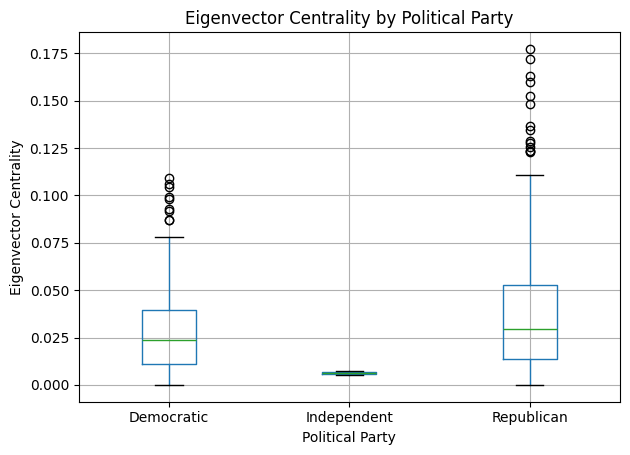

In [ ]:
# Boxplot of eigenvector centrality by party 
analysis_df.boxplot(
    column="eigenvector_centrality",
    by="party"
)

plt.title("Eigenvector Centrality by Political Party")
plt.suptitle("")
plt.xlabel("Political Party")
plt.ylabel("Eigenvector Centrality")
plt.tight_layout()
plt.show()

A boxplot of the eigenvector centrality further shows the spread of values of Democrats and Republicans. The Democratic centrality values are overall lower than the Republican values. 

# Visualization of network 

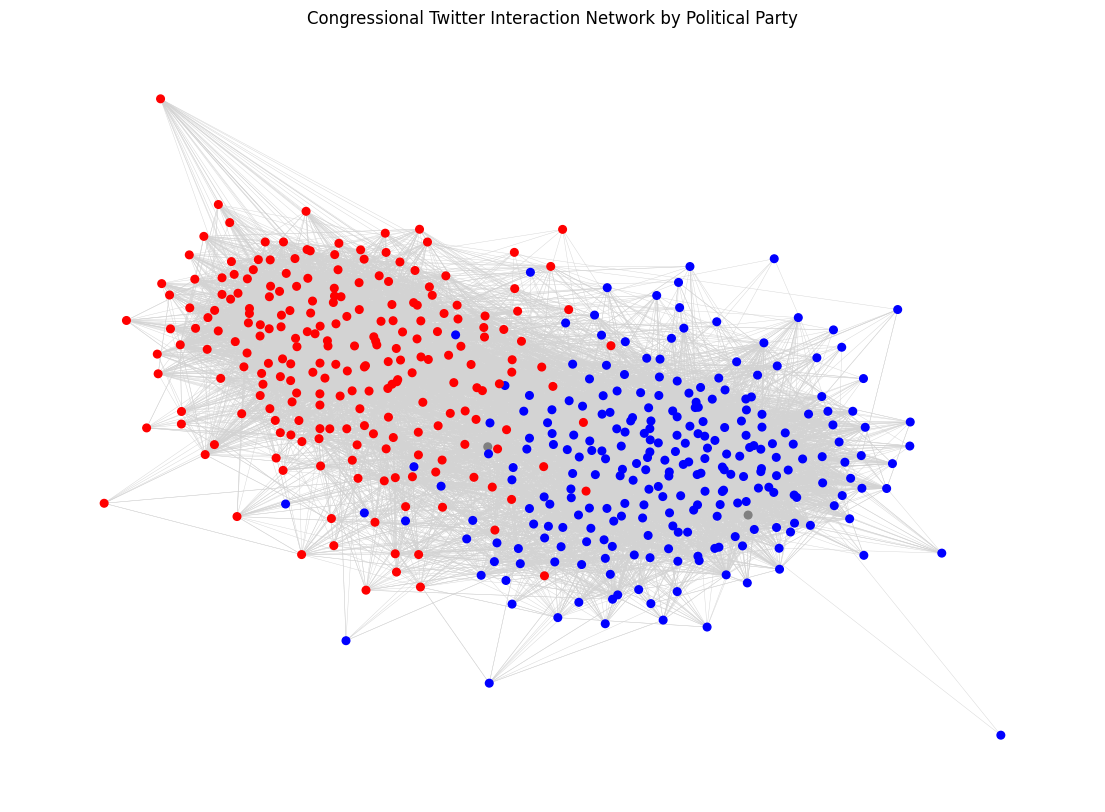

In [43]:
pos = nx.spring_layout(G, seed=213)

# Split nodes by political party
party_colors = {
    "democratic": "blue",
    "republican": "red",
    "independent": "gray"
}

node_colors = [
    party_colors.get(
        str(analysis_df.loc[analysis_df["node"] == node, "party"].iloc[0]).lower(),
        "gray"
    )
    for node in G.nodes()
]

# Draw the network
plt.figure(figsize=(14, 10))

nx.draw_networkx(
    G,
    pos,
    node_color= node_colors,
    node_size= 30,
    edge_color= "lightgray",
    width= 0.3,
    arrows = False,
    with_labels = False
)

plt.title("Congressional Twitter Interaction Network by Political Party")
plt.axis("off")
plt.show()

A visualization of the node map shows us that while each party primarily interacts with their own parties but there are interactions between Democratic and Republican members of Congress, rather than two completely separate party clusters. Some members appear more centrally positioned, while others are located toward the edges of the network. These patterns may reflect differences in connectivity, although node positions are influenced by the layout algorithm.

# Conclusion 

This project examined the Twitter interaction network of the 117th U.S. Congress to explore differences in connectivity between Democratic and Republican members. The network contained 475 members, and its undirected version had a diameter of 4, suggesting that members were connected through relatively short paths.

The centrality comparisons showed no statistically significant differences between Democrats and Republicans in degree centrality, in-degree centrality, or out-degree centrality. However, Republican members had significantly higher average eigenvector centrality (0.0409) than Democratic members (0.0280, p < 0.001). This suggests that Republican members tended to be connected to other well-connected members, even though the two parties had similar average levels of overall connectivity.

Overall, the findings suggest that party differences in this network were more apparent in the connectedness of members' contacts than in the number of interactions received or directed. However, these results describe Twitter interactions during the study period and do not necessarily reflect communication patterns outside the network.